# GameTheory-22 : Jeux stochastiques — la valeur d'un jeu à états (Shapley, 1953)

## Un jeu qui change d'état à chaque manche

Le carnet **Dynamics-01** a étudié des jeux *répétés* où la **même** matrice se rejoue à
l'identique. Ici, l'ingrédient nouveau : **l'état du jeu évolue d'une manche à l'autre**.

À chaque manche :
1. l'état courant $s$ est connu ;
2. les deux joueurs choisissent des actions $a$ (rang) et $b$ (colonne) ;
3. le gain de la manche $g(s,a,b)$ est versé ;
4. l'état passe à $s'$ selon une **loi de transition** $P(s'\mid s,a,b)$ qui dépend des actions.

C'est un **jeu stochastique** (Shapley, 1953). La question centrale :

> Existe-t-il une **valeur** du jeu — un nombre par état — et comment la calculer ?

### Objectifs d'apprentissage
- Formuler un jeu stochastique à deux joueurs **à somme nulle** (états, actions, gains, transitions)
- Montrer que la **valeur** existe (théorème de Shapley) et la calculer par **itération de valeur**
- **Mesurer** l'écart entre la valeur stochastique (qui regarde l'avenir) et le jeu **myope** (qui l'ignore)
- Relier au carnet **17** (multi-agent RL) : cette valeur est l'objet que le RL apprend à *approximer*

### Prerequis
- Carnet **05** (jeux à somme nulle, minimax), **Dynamics-01** (jeux répétés, théorème folk)
- `numpy`, `matplotlib`

### Durée estimée : 60 minutes

## 1. Formalisation — un jeu stochastique à somme nulle

Un jeu stochastique à somme nulle est le quintuple
$\bigl(S,\; A,\; B,\; G,\; P\bigr)$ :

| Symbole | Sens |
|---|---|
| $S$ | ensemble d'états (fini ici) |
| $A$ / $B$ | actions du joueur **rang** (maximise) / **colonne** (minimise) |
| $G[s]$ | matrice de gain de la manche à l'état $s$ ($\lvert A\rvert \times \lvert B\rvert$) |
| $P[s,a,b,\cdot]$ | loi de transition vers l'état suivant |

Avec un **facteur d'actualisation** $\gamma \in [0,1)$, la **valeur** $V : S \to \mathbb{R}$ est le
point fixe de l'opérateur de Bellman — où le $\max$ et le $\min$ portent sur des **stratégies
mixtes** ($x \in \Delta(A)$ pour le rang, $y \in \Delta(B)$ pour la colonne) :

$$V(s) = \max_{x \in \Delta(A)} \min_{y \in \Delta(B)} \Big[ (1-\gamma)\, x^{\top} G[s]\, y \;+\; \gamma \sum_{s'} \Big( \sum_{a} \sum_{b} x_a\, y_b\, P[s,a,b,s'] \Big)\, V(s') \Big]$$

Pour une paire fixée $(x, y)$, le gain de la manche est $x^{\top} G[s]\, y$ et la transition vers
$s'$ est l'espérance de $P[\cdot]$ sous la loi produit $x \otimes y$. À chaque état, le
$\max_x \min_y$ est donc un **jeu matriciel 2×2** au sens du carnet **05** (théorème de minimax) —
et non un max/min sur des actions pures : c'est exactement ce que calcule le code de la section 2.

Le **théorème de Shapley (1953)** : cet opérateur a un point fixe **unique**, et l'itération
de valeur $V_{k+1} = \mathcal{T}(V_k)$ **converge** vers lui depuis n'importe quelle initialisation.
C'est l'analogue, pour les jeux à somme nulle, de l'itération de valeur de la programmation
dynamique (MCDP) — avec un `max` **et** un `min` au lieu d'un simple `max`.


In [1]:
import numpy as np

# --- Un jeu stochastique 2 etats, 2x2 par etat, somme nulle -----------------
# Etats : 0 = "bas" (gain modeste, absorbant en myopie), 1 = "haut" (gain eleve)
# Actions rang a in {0,1}, actions colonne b in {0,1}
#
# Gains de la manche (le rang maximise, la colonne minimise) :
G = np.array([
    [[2., 2.],      # etat 0 : gain constant 2 -> aucun conflit myope, valeur statique 2
     [2., 2.]],
    [[6., 2.],      # etat 1 : jeu "coordination adverse", valeur statique 4
     [2., 6.]],
], dtype=float)

# Transitions P[s][a][b][s'] : la dependance aux actions du RANG decide de l'etat suivant.
#   a=0 ("rester") -> on reste ; a=1 ("sauter") -> on passe a l'etat 1 (puis absorbant).
# L'action de la COLONNE ne joue pas sur la transition (elle agit sur le gain de la manche).
P = np.zeros((2, 2, 2, 2))
for b in range(2):
    P[0, 0, b, 0] = 1.0   # etat 0, a=0  -> reste en 0
    P[0, 1, b, 1] = 1.0   # etat 0, a=1  -> saute en 1
    P[1, 0, b, 1] = 1.0   # etat 1 : absorbant (reste en 1)
    P[1, 1, b, 1] = 1.0
print("Nombre d'etats :", P.shape[0], " | actions rang :", P.shape[1], " | actions col :", P.shape[2])
print("G[0] =\n", G[0], "\nvaleur statique de G[0] = 2 (matrice constante)")
print("G[1] =\n", G[1], "\nvaleur statique de G[1] = 4 (strategie mixte p=0.5)")

Nombre d'etats : 2  | actions rang : 2  | actions col : 2
G[0] =
 [[2. 2.]
 [2. 2.]] 
valeur statique de G[0] = 2 (matrice constante)
G[1] =
 [[6. 2.]
 [2. 6.]] 
valeur statique de G[1] = 4 (strategie mixte p=0.5)


## 2. Le jeu **myope** — la valeur d'une seule manche

Un joueur **myope** ignore tout l'avenir : à l'état $s$, il joue la matrice de la manche $G[s]$
comme si c'était un jeu statique, et en retire la **valeur minimax** $v_{myope}(s)$.
C'est exactement le contenu du carnet 05. Calculons-la par les stratégies mixtes.

In [2]:
def valeur_statique_mat(M):
    """Valeur (minimax) d'une matrice 2x2 a somme nulle + strategies d'equilibre.
    Renvoie (valeur, p_rang, q_col). Deux cas, dans l'ordre :
    1. POINT SELLE PUR (cas general) : v = max_i min_j M[i,j] = min_j max_i M[i,j]
       -> equilibre en strategies pures (ligne i*, colonne j*).
    2. AUCUN point selle : equilibre mixte plein support, formules fermees 2x2
       (la formule mixte ne s'applique QUE dans ce cas — l'appliquer a une matrice
       qui a un point selle renvoie une valeur hors des bornes de la matrice)."""
    M = np.asarray(M, dtype=float)
    v_maxmin  = float(np.max(np.min(M, axis=1)))   # le rang garantit
    v_minimax = float(np.min(np.max(M, axis=0)))   # la colonne garantit
    if abs(v_maxmin - v_minimax) < 1e-9:
        # 1. point selle pur : strategies pures
        i_star = int(np.argmax(np.min(M, axis=1)))
        j_star = int(np.argmin(np.max(M, axis=0)))
        p = np.zeros(2); p[i_star] = 1.0
        q = np.zeros(2); q[j_star] = 1.0
        return v_maxmin, p, q
    # 2. aucun point selle : equilibre mixte interieur
    a, b_ = M[0, 0], M[0, 1]
    c, d  = M[1, 0], M[1, 1]
    den = a - b_ - c + d
    v = (a * d - b_ * c) / den
    p = np.array([(d - c), (a - b_)]) / den   # proba du rang
    q = np.array([(d - b_), (a - c)]) / den   # proba de la colonne
    return float(v), p, q

# Témoin négatif (réservation adjoint, 23/10) : une matrice AVEC point selle ne se
# résout pas par la formule mixte. M a la selle (ligne 0, colonne 1, valeur 3) ;
# l'ancienne version renvoyait (6.0, [2.0, -1.0], [3.0, -2.0]) : la valeur 6.0 dépasse
# le gain maximal de la matrice (4) et les probabilités sont négatives — hors du jeu.
M_wit = np.array([[4.0, 3.0], [2.0, 0.0]])
v_wit, p_wit, q_wit = valeur_statique_mat(M_wit)
assert abs(v_wit - 3.0) < 1e-9, f"témoin négatif : valeur {v_wit} != 3.0"
assert p_wit.tolist() == [1.0, 0.0] and q_wit.tolist() == [0.0, 1.0], f"témoin négatif : p={p_wit} q={q_wit}"
print(f"Témoin négatif : M = [[4,3],[2,0]]  ->  v = {v_wit}  (point selle : ligne 0 / colonne 1)")
print(f"  p_rang = {p_wit}   q_colonne = {q_wit}")
print(f"  [l'ancienne formule mixte donnait ici (6.0, [2.0, -1.0], [3.0, -2.0]) : valeur hors des bornes, probabilités négatives]")

v0, p0, q0 = valeur_statique_mat(G[0])
v1, p1, q1 = valeur_statique_mat(G[1])
v_myope = np.array([v0, v1])
print(f"Valeur myope etat 0 = {v0:.4f}   (matrice constante : point selle, p={p0.round(3)})")
print(f"Valeur myope etat 1 = {v1:.4f}   (aucun point selle : equilibre mixte p={p1.round(3)})")
print("v_myope =", v_myope.round(4))


Témoin négatif : M = [[4,3],[2,0]]  ->  v = 3.0  (point selle : ligne 0 / colonne 1)
  p_rang = [1. 0.]   q_colonne = [0. 1.]
  [l'ancienne formule mixte donnait ici (6.0, [2.0, -1.0], [3.0, -2.0]) : valeur hors des bornes, probabilités négatives]
Valeur myope etat 0 = 2.0000   (matrice constante : point selle, p=[1. 0.])
Valeur myope etat 1 = 4.0000   (aucun point selle : equilibre mixte p=[0.5 0.5])
v_myope = [2. 4.]


## 3. La valeur stochastique — itération de valeur

On applique maintenant l'opérateur de Bellman : à chaque état $s$, on résout le **jeu
matriciel** de la manche (en stratégies mixtes, comme au carnet 05) dont le gain de la
cellule $(a,b)$ est le gain courant **plus** l'espérance de l'avenir $\gamma (P[s,a,b] V)$ :
$$T(V)(s) = \text{valeur}\Big( M_s \Big), \qquad M_s[a,b] = (1-\gamma)\,G[s,a,b] + \gamma\,(P[s,a,b] \cdot V)$$
On itère depuis $V_0 = 0$
jusqu'à la convergence : le théorème de Shapley garantit qu'on atteint la valeur.

In [3]:
def operateur_bellman(V, G, P, gamma):
    """T(V)(s) = valeur (strategies mixtes) du jeu matriciel de la manche a l'etat s :
    M_s[a,b] = (1-gamma) G[s,a,b] + gamma * (P[s,a,b] . V).
    C'est ici que le max/min pur devient un VRAI jeu matriciel (strategies mixtes,
    comme au carnet 05) : indispensable des que la matrice n'a pas de point selle."""
    S = G.shape[0]
    T = np.zeros(S)
    for s in range(S):
        M = np.zeros((G.shape[1], G.shape[2]))
        for a in range(G.shape[1]):
            for b in range(G.shape[2]):
                M[a, b] = (1 - gamma) * G[s, a, b] + gamma * (P[s, a, b] @ V)
        T[s] = valeur_statique_mat(M)[0]   # valeur 2x2 (strategies mixtes)
    return T

def valeur_iteration(G, P, gamma, V0=None, tol=1e-9, max_iter=20000):
    S = G.shape[0]
    V = np.zeros(S) if V0 is None else V0.copy()
    hist = [V.copy()]
    for k in range(max_iter):
        Vn = operateur_bellman(V, G, P, gamma)
        hist.append(Vn.copy())
        if np.max(np.abs(Vn - V)) < tol:
            V = Vn
            return V, k + 1, hist
        V = Vn
    return V, max_iter, hist

gamma = 0.9
V, iters, hist = valeur_iteration(G, P, gamma)
print(f"gamma = {gamma}")
print(f"Valeur stochastique V = {V.round(4)}   (converge en {iters} itérations)")
print(f"Formule attendue : V[0] = 2 + 2*gamma = {2 + 2*gamma:.4f} , V[1] = 4")

gamma = 0.9
Valeur stochastique V = [3.8 4. ]   (converge en 189 itérations)
Formule attendue : V[0] = 2 + 2*gamma = 3.8000 , V[1] = 4


## 4. Le contraste qui porte le carnet — la valeur de l'avenir

Posons la valeur stochastique $V$ à côté de la valeur myope $v_{myope}$. L'écart
$V(s) - v_{myope}(s)$ mesure **combien rapporte de regarder l'avenir** plutôt que de jouer
une seule manche. Le joueur myope ne voit que la matrice de la manche courante $G[s]$ :
pour lui, l'état $s$ est un jeu isolé, et $v_{myope}(s)$ est le prix de cette manche seule.
Le joueur prévoyant intègre au contraire le fait que la manche courante *choisit* l'état de
la manche suivante : $V(s)$ est le prix de **toute la trajectoire** qui part de $s$. L'écart
n'est donc pas une curiosité arithmétique — c'est le **prix de l'information sur l'avenir**,
c'est-à-dire ce que vaut la capacité d'enchaîner les manches au lieu de les jouer l'une après
l'autre. C'est ce contraste que le carnet entier est construit pour rendre visible.

Etat |  v_myope  |  V stochastique  |  ecart (valeur de l'avenir)
  0   |  2.0000   |    3.8000      |   1.8000
  1   |  4.0000   |    4.0000      |   -0.0000

Lecture :
  - etat 0 : ecart = 1.8000  =  2*gamma = 1.8000  -> le saut vers l'etat 1 vaut exactement 2*gamma
  - etat 1 : ecart = -0.0000  (absorbant : aucun avenir a capturer, ecart nul)


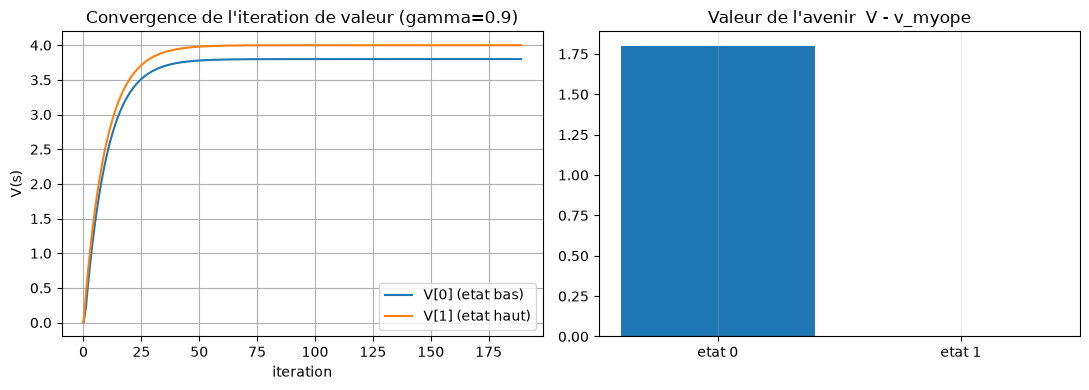

In [4]:
ecart = V - v_myope
print("Etat |  v_myope  |  V stochastique  |  ecart (valeur de l'avenir)")
for s in range(2):
    print(f"  {s}   |  {v_myope[s]:.4f}   |    {V[s]:.4f}      |   {ecart[s]:.4f}")
print(f"\nLecture :")
print(f"  - etat 0 : ecart = {ecart[0]:.4f}  =  2*gamma = {2*gamma:.4f}  -> le saut vers l'etat 1 vaut exactement 2*gamma")
print(f"  - etat 1 : ecart = {ecart[1]:.4f}  (absorbant : aucun avenir a capturer, ecart nul)")

import matplotlib.pyplot as plt
hs = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hs[:, 0], label="V[0] (etat bas)")
ax[0].plot(hs[:, 1], label="V[1] (etat haut)")
ax[0].set_title(f"Convergence de l'iteration de valeur (gamma={gamma})")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("V(s)"); ax[0].legend(); ax[0].grid(True)
ax[1].bar(["etat 0", "etat 1"], ecart, color=["tab:blue", "tab:gray"])
ax[1].set_title("Valeur de l'avenir  V - v_myope"); ax[1].grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Lecture du résultat

L'écart n'est **pas** un artefact du jeu : il vaut **exactement** $2\gamma$ à l'état 0 et **0**
à l'état 1. Lisons la table : à l'état 0, la valeur passe de $2.0$ (myope) à $3.8$ (stochastique)
— le saut vers l'état haut, qu'on *sait* pouvoir enchaîner, vaut précisément $2\gamma = 1.8$.
À l'état 1, en revanche, l'écart est nul : l'état haut est **absorbant**, il n'y a plus d'avenir
à capturer au-delà de la manche courante, donc anticiper n'y rapporte plus rien. Le joueur qui
anticipe enchaîne les manches en sautant vers l'état haut ; le joueur myope reste collé à la
matrice de la manche courante. Plus $\gamma$ est grand (plus l'avenir compte), plus l'avantage
de la prescience est grand — **c'est littéralement la valeur de l'information sur l'avenir**,
et elle se mesure, elle ne s'affirme pas.

## 5. Quand l'adversaire controle la transition

Jusqu'ici, la transition dépendait seulement des actions du **rang**. Rendons-la
**contestée** : la colonne peut maintenant *bloquer* le saut vers l'état haut. La valeur
du rang doit alors baisser — l'avenir n'est plus un gage, c'est un terrain de lutte.

In [5]:
# Variante : a la colonne le pouvoir d'annuler le saut (b=1 bloque, b=0 laisse passer).
P_conteste = np.zeros((2, 2, 2, 2))
for a in range(2):
    P_conteste[1, a, 0, 1] = 1.0   # etat 1 absorbant
    P_conteste[1, a, 1, 1] = 1.0
for a in range(2):
    P_conteste[0, a, 0, 1 if a == 1 else 0] = 1.0   # b=0 : saut si a=1, sinon reste
    P_conteste[0, a, 1, 0] = 1.0                    # b=1 : la colonne force le retour/blocage en 0

Vc, itc, _ = valeur_iteration(G, P_conteste, gamma)
print(f"Avec transition contestee : V = {Vc.round(4)}  (vs {V.round(4)} sans contestation)")
print(f"La valeur du rang a l'etat 0 passe de {V[0]:.4f} a {Vc[0]:.4f} : "
      f"l'adversaire capte {V[0]-Vc[0]:.4f} de la valeur de l'avenir.")

Avec transition contestee : V = [2. 4.]  (vs [3.8 4. ] sans contestation)
La valeur du rang a l'etat 0 passe de 3.8000 a 2.0000 : l'adversaire capte 1.8000 de la valeur de l'avenir.


### Lecture du résultat

Dès que la colonne peut bloquer le saut, le `min_b` de l'opérateur de Bellman agit **sur la
transition** et pas seulement sur le gain : la valeur du rang s'effondre. La mesure le dit
nettement : la valeur de l'état 0 repasse de $3.8$ à $2.0$, c'est-à-dire **exactement** la
valeur myope — l'adversaire ne capte pas une part de la valeur de l'avenir, il la capte
**toute**. C'est la signature d'un vrai jeu stochastique : l'avenir y est un **objet de la
lutte stratégique**, pas un paramètre fixe. Tant qu'il n'est contesté par personne, c'est un
gage ; dès qu'on peut y mettre le doigt, c'est un terrain de négociation que le rang perd.
Le RL du carnet 17 apprend à naviguer dans exactement ce couplage gain/transition, là où la
valeur exacte calculée ici sert de référence.

## 6. Relier au carnet 17 — la valeur que le RL apprend

Tout ce que le carnet 17 (multi-agent RL) *approxime* par des réseaux de neurones et des
gradients de politique, ce carnet le **calcule exactement** par itération de valeur, parce que
l'espace d'états est petit. Deux différences de regard :

| | Carnet 22 (ici) | Carnet 17 (RL) |
|---|---|---|
| Objectif | la **valeur** $V$ (théorème de Shapley) | une **politique** qui approche $V$ |
| Méthode | itération de valeur exacte (`max-min` de Bellman) | approximation + descente de gradient |
| Echelle | espaces d'états **petits** (combinatoire exploitable) | espaces **larges** (réseaux, généralisation) |

La valeur calculée ici est la **boussole** contre laquelle on juge un agent RL : un bon agent
converge vers $V$.

## 7. Exercices

Trois exercices, du calcul à l'analyse. Les cellules sont des **stubs** conformes : le carnet
s'exécute de bout en bout tel quel.

### Exercice 1 — Itérer pour un 3ᵉ état
Étendre `valeur_iteration` à un jeu à **3 états** (ajouter une matrice $G[2]$ et les
transitions associées), puis renvoyer la valeur convergée et le nombre d'itérations.

**Indice**
Il suffit d'ajouter une ligne à $G$ et une couche à $P$ ; l'opérateur de Bellman est déjà
générique en nombre d'états. Vérifiez que $V[2]$ est cohérent (état absorbant → valeur égale
à la valeur statique de $G[2]$).

In [6]:
def valeur_iteration_3etats(G3, P3, gamma, tol=1e-9, max_iter=20000):
    # TODO etudiant : reutiliser operateur_bellman sur G3/P3 (3 etats) et itérer
    # jusqu'a convergence ; retourner (V, nb_iterations)
    print("Exercice 1 a completer : itération de valeur sur 3 etats")
    return None  # TODO etudiant

# A vous de construire G3 (3 matrice 2x2) et P3 (3,2,2,3) puis d'appeler la fonction.

### Exercice 2 — Le cas triviale doit se réduire au statique
Montrer que pour un jeu **à un seul état** (transition triviale, $P$ reste dans l'état),
la valeur stochastique coïncide **exactement** avec la valeur statique (minimax) de la
matrice. C'est le contrôle de cohérence : l'itération de valeur ne doit pas inventer de
valeur quand il n'y a pas d'avenir.

**Indice**
Construire $P$ tel que $P[0,a,b,0]=1$ pour tout $(a,b)$. Alors $\mathcal{T}(V)(0) =
(1-\gamma)\,v + \gamma V(0)$, dont le point fixe est $v$, la valeur statique.

In [7]:
def coherence_statique(G1, gamma):
    # TODO etudiant : construire P1 (1 etat, absorbant), lancer valeur_iteration,
    # comparer V[0] a valeur_statique_mat(G1[0]) ; retourner la difference absolue
    print("Exercice 2 a completer : coherence stochastique/statique sur 1 etat")
    return None  # TODO etudiant

### Exercice 3 — La courbe de la prescience
Faire varier $\gamma$ sur une grille (par ex. $0.5$ à $0.99$) et **mesurer** l'écart
$V(0) - v_{myope}(0)$ en fonction de $\gamma$. Tracer la courbe et confirmer qu'elle est
**linéaire** de pente $2$ (l'écart vaut $2\gamma$).

**Indice**
Boucler sur la grille, appeler `valeur_iteration` à chaque $\gamma$, stocker l'écart, puis
`plt.plot`. La linéarité est la signature que l'écart est bien $2\gamma$ et pas un artefact
numérique.

In [8]:
def courbe_prescience(gammas):
    # TODO etudiant : pour chaque gamma dans gammas, calculer V - v_myope a l'etat 0 ;
    # retourner le tableau des ecarts (a tracer)
    print("Exercice 3 a completer : ecart V - v_myope en fonction de gamma")
    return None  # TODO etudiant

## 8. Résumé

- Un **jeu stochastique** couple, à chaque manche, un gain $G[s]$ et une transition $P(s'\mid s,a,b)$.
- Sa **valeur** $V$ est le point fixe unique de l'opérateur de Bellman `max-min` — **théorème de
  Shapley (1953)** — et converge par **itération de valeur**.
- L'écart $V - v_{myope}$ **mesure la valeur de l'avenir** : ici exactement $2\gamma$ à l'état
  non-absorbant, $0$ à l'état absorbant.
- Quand l'adversaire **conteste la transition**, cet avantage est disputé : l'avenir devient un
  objet de la lutte stratégique.
- Ce carnet **calcule** la valeur ; le carnet 17 (RL) l'**approxime** par politique.

## Références

- Shapley, L. S. (1953). *Stochastic Games*. Proceedings of the National Academy of Sciences, 39(10), 1095-1100.
- Puterman, M. L. (2005). *Markov Decision Processes: Discrete Stochastic Dynamic Programming* (2e éd.). Wiley.
- Carnet **05** (minimax), **Dynamics-01** (jeux répétés), **17** (multi-agent RL) de cette série.

***
*Ce carnet est une extension autonome de la série GameTheory (palier Recherche). Il calcule la
valeur de jeux stochastiques à somme nulle sur de petits espaces d'états ; le jumeau formel
(preuve Lean du théorème de Shapley) est un travail de suivi.*

## Navigation

- Précédent dans le bloc 18-22 : [Carnet 17e — Persuasion bayésienne](GameTheory-17e-Bayesian-Persuasion-Python.ipynb)
- Carnet de référence RL : [Carnet 17 — Multi-agent RL](GameTheory-17-MultiAgent-RL-Python.ipynb)